# Photons in the Sentinel-2C bands

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_brno_en.ipynb)

**OpenSkyLab · notebook for the visual** [Rope and photons](https://openskylab.space/edu_viz_rope_and_photons.html) · [česká verze](rope_and_photons_brno_cs.ipynb)

In the visual you saw that a wave on a rope obeys c = λ · f and that both amplitude and frequency carry energy. Light is different: the energy of one photon depends only on frequency, E = h · f, and brightness is the number of photons. Here you compute it for the real bands of the Sentinel-2 satellite.

**Goal:** from the metadata of a real Sentinel-2 scene, compute the frequency, photon energy and photon flux in each band and work out which detector each band needs.

**Data:** the product metadata of Sentinel-2C L1C, tile 33UXQ (around Brno), 5 February 2025 (`MTD_MSIL1C.xml` from the Google Cloud public archive): central wavelengths, spectral response of the bands and top-of-atmosphere solar irradiance. About 50 kB is downloaded.

**Tasks:** six. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 40 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and data

In [1]:
import re, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import h, c, e, k   # Planck constant, speed of light, elementary charge, Boltzmann constant

# metadata of one real Sentinel-2C L1C scene (tile 33UXQ, 5 February 2025)
URL = ("https://storage.googleapis.com/gcp-public-data-sentinel-2/tiles/33/U/XQ/"
       "S2C_MSIL1C_20250205T095231_N0511_R079_T33UXQ_20250205T115121.SAFE/MTD_MSIL1C.xml")
xml = requests.get(URL, timeout=60).text
print(f"downloaded {len(xml) / 1000:.0f} kB")

downloaded 49 kB


In [2]:
# from the XML we take for each band: name, central wavelength, spectral response and solar irradiance E0
rows, srf = [], {}
for m in re.finditer(r'<Spectral_Information bandId="(\d+)" physicalBand="(\w+)">(.*?)</Spectral_Information>', xml, re.S):
    bid, name, body = int(m.group(1)), m.group(2), m.group(3)
    lmin = float(re.search(r'<MIN unit="nm">([\d.]+)', body).group(1))
    vals = np.array(re.search(r"<VALUES>(.*?)</VALUES>", body).group(1).split(), float)
    srf[name] = (lmin + np.arange(len(vals)), vals)          # 1 nm step
    e0 = float(re.search(rf'<SOLAR_IRRADIANCE bandId="{bid}"[^>]*>([\d.]+)', xml).group(1))
    rows.append({"band": name,
                 "lambda_nm": float(re.search(r'<CENTRAL unit="nm">([\d.]+)', body).group(1)),
                 "E0_W_m2_um": e0})
bands = pd.DataFrame(rows).set_index("band")
bands

,lambda_nm,E0_W_m2_um
band,,
B1,444.2,1914.61
B2,489.0,1972.03
B3,560.6,1822.48
B4,666.5,1506.74
B5,707.1,1410.66
B6,741.1,1287.62
B7,784.7,1154.97
B8,834.6,1037.17
B8A,865.6,957.92


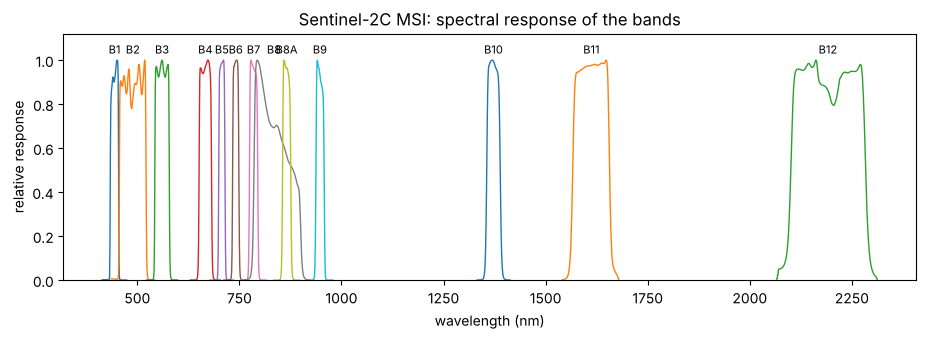

In [3]:
# spectral response of the bands: how strongly the detector responds to each wavelength
fig, ax = plt.subplots(figsize=(11, 3.2))
for name, (wl, r) in srf.items():
    ax.plot(wl, r, lw=1)
    ax.text(bands.lambda_nm[name], 1.03, name, ha="center", fontsize=8)
ax.set(xlabel="wavelength (nm)", ylabel="relative response", ylim=(0, 1.12), title="Sentinel-2C MSI: spectral response of the bands")
plt.show()

## 2. Wavelength and frequency

In [4]:
lam = bands.lambda_nm * 1e-9               # m
bands["f_THz"] = c / lam / 1e12            # f = c / λ
bands["lambda_x_f"] = lam * bands.f_THz * 1e12
bands[["lambda_nm", "f_THz", "lambda_x_f"]].round(1)

,lambda_nm,f_THz,lambda_x_f
band,,,
B1,444.2,674.9,299792458.0
B2,489.0,613.1,299792458.0
B3,560.6,534.8,299792458.0
B4,666.5,449.8,299792458.0
B5,707.1,424.0,299792458.0
B6,741.1,404.5,299792458.0
B7,784.7,382.0,299792458.0
B8,834.6,359.2,299792458.0
B8A,865.6,346.3,299792458.0


> **✏️ Task 1.** The `lambda_x_f` column is the same for every band. What does it express and what does it correspond to on the rope in the visual? How many times higher is the frequency of band B2 (blue) than of B12 (SWIR 2)?

*Your answer:* 

## 3. Energy of one photon

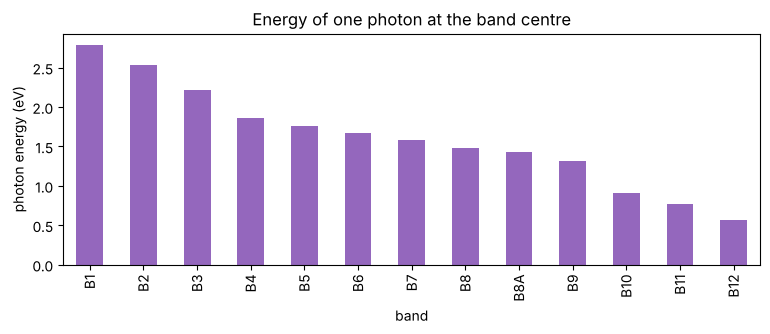

blue (B2) / red (B4) photon: 1.36 ×


In [5]:
bands["E_photon_eV"] = h * c / lam / e     # E = h·f = h·c/λ, converted to electronvolts
ax = bands.E_photon_eV.plot.bar(figsize=(9, 3), color="tab:purple")
ax.set(ylabel="photon energy (eV)", title="Energy of one photon at the band centre")
plt.show()
print(f"blue (B2) / red (B4) photon: {bands.E_photon_eV['B2'] / bands.E_photon_eV['B4']:.2f} ×")

> **✏️ Task 2.** Check the energy ratio of the blue and red photon from the wavelengths alone, without constants. Why is the ratio of λ enough? How does the energy of one photon change when the blue light is twice as bright?

*Your answer:* 

## 4. Brightness is the number of photons

The metadata give the top-of-atmosphere solar irradiance E0 in W·m⁻²·µm⁻¹ for each band. Dividing it by the energy of one photon gives the number of photons per second falling on one square metre within one micrometre of spectrum.

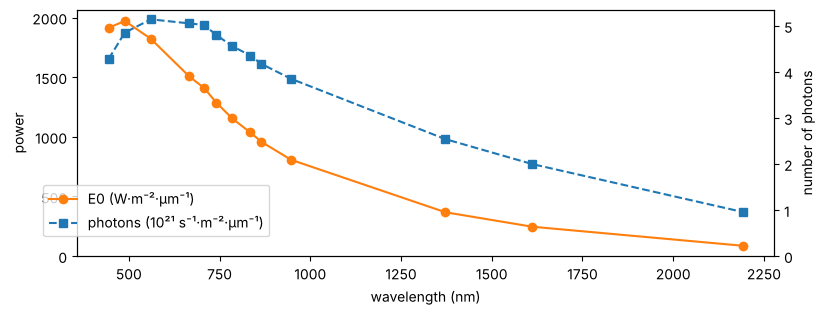

,E0_W_m2_um,E_photon_eV,photons_per_s_m2_um
band,,,
B1,1.91e+03,2.79,4.28e+21
B2,1.97e+03,2.54,4.85e+21
B3,1.82e+03,2.21,5.14e+21
B4,1.51e+03,1.86,5.06e+21
B5,1.41e+03,1.75,5.02e+21
B6,1.29e+03,1.67,4.8e+21
B7,1.15e+03,1.58,4.56e+21
B8,1.04e+03,1.49,4.36e+21
B8A,958,1.43,4.17e+21


In [6]:
bands["photons_per_s_m2_um"] = bands.E0_W_m2_um / (bands.E_photon_eV * e)
fig, ax1 = plt.subplots(figsize=(9, 3.2))
ax1.plot(bands.lambda_nm, bands.E0_W_m2_um, "o-", c="tab:orange", label="E0 (W·m⁻²·µm⁻¹)")
ax2 = ax1.twinx()
ax2.plot(bands.lambda_nm, bands.photons_per_s_m2_um / 1e21, "s--", c="tab:blue", label="photons (10²¹ s⁻¹·m⁻²·µm⁻¹)")
ax1.set(xlabel="wavelength (nm)", ylabel="power"); ax2.set(ylabel="number of photons", ylim=(0, None)); ax1.set_ylim(0)
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.15)); plt.show()
bands[["E0_W_m2_um", "E_photon_eV", "photons_per_s_m2_um"]].style.format("{:.3g}")

> **✏️ Task 3.** The power E0 falls more than twentyfold from blue (B2) to SWIR 2 (B12). Does the number of photons fall in the same way? Explain the difference. In which band does the most photons per micrometre fall on a square metre, and why is it not the band with the highest E0?

*Your answer:* 

## 5. Which bands a silicon chip can see

A photon frees an electron in a detector only if its energy is at least the band gap of the material. For silicon it is about 1.12 eV. We compute the cut-off wavelength and check how much of each band's response lies below it.

In [7]:
Eg = 1.12          # ◀ parameter: band gap in eV (silicon 1.12; InGaAs about 0.75; HgCdTe 0.1–0.5 depending on composition)
lam_cut = h * c / (Eg * e) * 1e9
print(f"cut-off wavelength: {lam_cut:.0f} nm")
share = {name: r[wl <= lam_cut].sum() / r.sum() for name, (wl, r) in srf.items()}
bands["share_detectable"] = pd.Series(share)
bands[["lambda_nm", "E_photon_eV", "share_detectable"]].style.format({"lambda_nm": "{:.0f}", "E_photon_eV": "{:.2f}", "share_detectable": "{:.0%}"})

cut-off wavelength: 1107 nm


,lambda_nm,E_photon_eV,share_detectable
band,,,
B1,444,2.79,100%
B2,489,2.54,100%
B3,561,2.21,100%
B4,666,1.86,100%
B5,707,1.75,100%
B6,741,1.67,100%
B7,785,1.58,100%
B8,835,1.49,100%
B8A,866,1.43,100%


> **✏️ Task 4.** Which Sentinel-2 bands would a silicon detector capture fully, partly and not at all? Set `Eg = 0.75` (InGaAs) and run the cell again. What changed? Sentinel-2 uses HgCdTe detectors for bands B10 to B12: why?

*Your answer:* 

## 6. Thermal radiation and radar

We compare photons from a thermal band (10.9 µm, as in Landsat 8 TIRS) and from the Sentinel-1 radar (5.405 GHz) with the typical thermal energy in a detector at room temperature, k · T.

In [8]:
T = 300            # ◀ parameter: detector temperature in kelvin
kT = k * T / e
other = pd.DataFrame({
    "lambda_m": [h * c / (10 * e), 490e-9, 1610e-9, 10.9e-6, c / 5.405e9],
}, index=["ionisation (10 eV)", "B2 blue", "B11 SWIR", "thermal 10.9 µm", "radar C 5.405 GHz"])
other["E_eV"] = h * c / other.lambda_m / e
other["E_over_kT"] = other.E_eV / kT
print(f"k·T at {T} K = {kT * 1000:.1f} meV")
other.style.format({"lambda_m": "{:.3g}", "E_eV": "{:.3g}", "E_over_kT": "{:.3g}"})

k·T at 300 K = 25.9 meV


,lambda_m,E_eV,E_over_kT
ionisation (10 eV),1.24e-07,10,387
B2 blue,4.9e-07,2.53,97.9
B11 SWIR,1.61e-06,0.77,29.8
thermal 10.9 µm,1.09e-05,0.114,4.4
radar C 5.405 GHz,0.0555,2.24e-05,0.000865


> **✏️ Task 5.** A thermal photon has only about four times the energy of k · T, a radar photon is more than a thousand times weaker than k · T. Why are thermal cameras with photon detectors cooled, and why do a microbolometer and a radar antenna measure heating or the electric field of the wave rather than individual photons? Set `T = 77` (liquid nitrogen) and compare.

*Your answer:* 

> **✏️ Task 6.** At what wavelength does a photon have an energy of 10 eV (the approximate ionisation threshold)? Which part of the spectrum is it? Chemical bonds in molecules have energies of a few eV. Explain why a single UV photon can damage DNA while a strong radar signal carries more energy in total and still breaks no bond and ionises nothing.

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for another Sentinel-2 satellite (2A, 2B or 2C). Compare the central wavelengths of the bands and the E0 values: by how many nanometres do bands of the same name differ, and why must anyone who builds a time series from several satellites take this into account?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2025, ESA; L1C metadata from the Google Cloud public archive (`gcp-public-data-sentinel-2`). Licence: [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice), free use with attribution.
- Constants h, c, e, k: exactly defined SI values since 2019, taken from `scipy.constants`.
- Silicon band gap 1.12 eV at 300 K: Sze, S. M., Ng, K. K. (2007). *Physics of Semiconductor Devices*, 3rd ed. Wiley.
- Sentinel-1 radar frequency (C band) 5.405 GHz: ESA, Sentinel-1 User Handbook.

### How to cite

OpenSkyLab (2026). Photons in the Sentinel-2C bands [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_brno_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*